#### Découverte des données

In [1]:
#%pip install kagglehub
#%pip install ultralytics

In [2]:
#%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn python-dotenv opencv-python pillow ipykernel mlflow streamlit
#%pip  install kagglehub
#%pip uninstall -y tensorflow protobuf
#%pip install -q tensorflow protobuf

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")

print(path)

100%|██████████| 133M/133M [00:00<00:00, 140MB/s]  

Extracting files...


/root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1


In [4]:
import torch
import ultralytics
import cv2
import pandas as pd
import numpy as np
import warnings
import os
import matplotlib.pyplot as plt
import random
warnings.simplefilter('ignore')
from collections import Counter
from pathlib import Path
import shutil

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


#### Vérification et nettoyage

In [5]:
DATASET_DIR = Path(path)

#WORK_DIR = Path("/kaggle/working/NeuroVisoon_AI")

#WORK_DIR.mkdir(parents=True, exist_ok=True)

#print("Dataset source present : ", DATASET_DIR.exists())
#print("Dataset sourcede Travail present : ", WORK_DIR.exists())
print("Chemin de Travail: ", DATASET_DIR.exists())

Chemin de Travail:  True


In [6]:
#classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
#
#for classe in classes:
#      (WORK_DIR / "Test" / classe / "images").mkdir(parents=True, exist_ok=True)
#      (WORK_DIR / "Test" / classe / "labels").mkdir(parents=True, exist_ok=True)
#
#print('Dossiers crées dans ', WORK_DIR / 'Test')

In [7]:
for dossier in [DATASET_DIR, DATASET_DIR / 'Train', DATASET_DIR / 'Val']:
      print(f"\n ---{dossier}---")
      if dossier.exists():
            for element in list(dossier.iterdir())[:15]:
                  print(element.name)
      else:
            print("Ce dossier n'existe pas.")


 ---/root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1---
Train
Val

 ---/root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1/Train---
Glioma
Meningioma
No Tumor
Pituitary

 ---/root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1/Val---
Glioma
Meningioma
No Tumor
Pituitary


In [8]:
EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp"}
for split in ["Train", "Val"]:
      split_dir = DATASET_DIR /split

      print(f"\n {'=' *20} {split} {'=' * 20}")

      for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                  continue
            print(f"\nClasse : {class_dir.name}")

            for sous_dossier in ['images', 'labels']:
                  dossier = class_dir / sous_dossier

                  if not dossier.is_dir():
                        print(f"{sous_dossier} : Dossier Introuvable")
                        continue
                  
                  fichiers = [fichier for fichier in dossier.iterdir() if fichier.is_file()]

                  if sous_dossier == 'images':

                        fichiers_valides = [
                              fichier for fichier in fichiers
                              if fichier.suffix.lower() in EXTENSIONS_IMAGES
                        ]
                  else:
                        fichiers_valides = [
                              fichier for fichier in fichiers
                              if fichier.suffix.lower() == ".txt"
                        ]

                  extensions = Counter(fichier.suffix.lower()
                              for fichier in fichiers
                        )

                  print(f"\nClasse : {sous_dossier}")
                  print(f"Nombre de fichiers totals : {len(fichiers)}")
                  print(f"Nombre de fichiers attendus : {len(fichiers_valides)}")
                  print(f"Extensions : {dict(extensions)}")

                  print("Exemples:")
                  for fichier in fichiers[:5]:
                        print(" ", fichier.name)
            



 ==================== Train ====================

Classe : Glioma

Classe : images
Nombre de fichiers totals : 1153
Nombre de fichiers attendus : 1153
Extensions : {'.jpg': 1153}
Exemples:
  Te-glTr_0000.jpg
  Te-glTr_0005.jpg
  Te-glTr_0007.jpg
  Te-gl_0014.jpg
  Te-gl_0015.jpg

Classe : labels
Nombre de fichiers totals : 1153
Nombre de fichiers attendus : 1153
Extensions : {'.txt': 1153}
Exemples:
  Te-glTr_0000.txt
  Te-glTr_0005.txt
  Te-glTr_0007.txt
  Te-gl_0014.txt
  Te-gl_0015.txt

Classe : Meningioma

Classe : images
Nombre de fichiers totals : 1449
Nombre de fichiers attendus : 1449
Extensions : {'.jpg': 1449}
Exemples:
  Tr-meTr_0008.jpg
  Tr-meTr_0009.jpg
  Tr-me_0010.jpg
  Tr-me_0011.jpg
  Tr-me_0017.jpg

Classe : labels
Nombre de fichiers totals : 1449
Nombre de fichiers attendus : 1449
Extensions : {'.txt': 1449}
Exemples:
  Tr-meTr_0008.txt
  Tr-meTr_0009.txt
  Tr-me_0010.txt
  Tr-me_0011.txt
  Tr-me_0017.txt

Classe : No Tumor

Classe : images
Nombre de fichiers total

In [9]:
#Verifier la correspondance entre images et annotations

EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp"}

def verifier_paires(split_dir):
      results = {}

      for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                  continue

            images_dir = class_dir / "images"
            labels_dir = class_dir / "labels"

            if not images_dir.is_dir() or not labels_dir.is_dir():
                  print(f"Erreur Strucure inattendue : {class_dir}")
                  continue

            images = {
                  f.stem: f
                  for f in images_dir.iterdir()
                  if f.is_file() and f.suffix.lower() in EXTENSIONS_IMAGES
            }

            labels = {
                  f.stem : f
                  for f in labels_dir.iterdir()
                  if f.is_file() and f.suffix.lower() == '.txt'
            }

            images_sans_labels = sorted(set(images) - set(labels))
            labels_sans_images = sorted(set(labels) - set(images))


            results[class_dir.name] = {
                  "images" : len(images),
                  "labels" : len(labels),
                  "images_sans_labels" : images_sans_labels,
                  "labels_sans_images" : labels_sans_images,
            }

            print(f"\n---{class_dir.name}---")
            print(f"Images : {len(images)}")
            print(f"Annotations : {len(labels)}")
            print(f"Images sans annotations: {len(images_sans_labels)}")
            print(f"Annotations sans images: {len(labels_sans_images)}")

            if images_sans_labels:
                  print("Exemple d'images sans annotation : ", images_sans_labels[:5])
            if labels_sans_images:
                  print("Exemple d'annotations sans image : ", labels_sans_images[:5])
      return results

results_train = verifier_paires(DATASET_DIR / 'Train')
results_val = verifier_paires(DATASET_DIR / 'Val')


---Glioma---
Images : 1153
Annotations : 1153
Images sans annotations: 0
Annotations sans images: 0

---Meningioma---
Images : 1449
Annotations : 1449
Images sans annotations: 0
Annotations sans images: 0

---No Tumor---
Images : 711
Annotations : 711
Images sans annotations: 0
Annotations sans images: 0

---Pituitary---
Images : 1424
Annotations : 1424
Images sans annotations: 0
Annotations sans images: 0

---Glioma---
Images : 136
Annotations : 136
Images sans annotations: 0
Annotations sans images: 0

---Meningioma---
Images : 140
Annotations : 140
Images sans annotations: 0
Annotations sans images: 0

---No Tumor---
Images : 100
Annotations : 100
Images sans annotations: 2
Annotations sans images: 2
Exemple d'images sans annotation :  ['image(55)', 'image(61)']
Exemple d'annotations sans image :  ['image(53)', 'image(60)']

---Pituitary---
Images : 136
Annotations : 136
Images sans annotations: 0
Annotations sans images: 0


In [10]:
non_tumor_val = DATASET_DIR / 'Val' / 'No Tumor'

images_dir = non_tumor_val /'images'
labels_dir = non_tumor_val /'labels'

noms_a_verifier = ['image(55)', 'image(61)','image(53)', 'image(60)']

for nom in noms_a_verifier:
      print(f"\n---{nom}---")

      for dossier in[images_dir, labels_dir]:
            fichiers = list(dossier.glob(f'{nom}.*'))

            if fichiers:
                  for fichier in fichiers:
                    print(f"Trouvé : {fichier.name}")
                      
                      
            else:
                  print(f"Aucun fichier correspondant dans {dossier.name}")



---image(55)---
Trouvé : image(55).jpg
Aucun fichier correspondant dans labels

---image(61)---
Trouvé : image(61).jpg
Aucun fichier correspondant dans labels

---image(53)---
Aucun fichier correspondant dans images
Trouvé : image(53).txt

---image(60)---
Aucun fichier correspondant dans images
Trouvé : image(60).txt


In [11]:
#Visualisation des 2 labels sans images

for nom in ['image(53)', 'image(60)']:
      fichier_label = labels_dir / f"{nom}.txt"

      print(f"\n ---{fichier_label.name} ---")

      if fichier_label.exists():
            contenue = fichier_label.read_text(encoding='utf-8').strip()

            if contenue:
                  print(contenue)
            else:
                  print("Annotation vide")


 ---image(53).txt ---
2 0.506818 0.494545 0.913636 0.930909

 ---image(60).txt ---
2 0.502119 0.514831 0.572034 0.682203


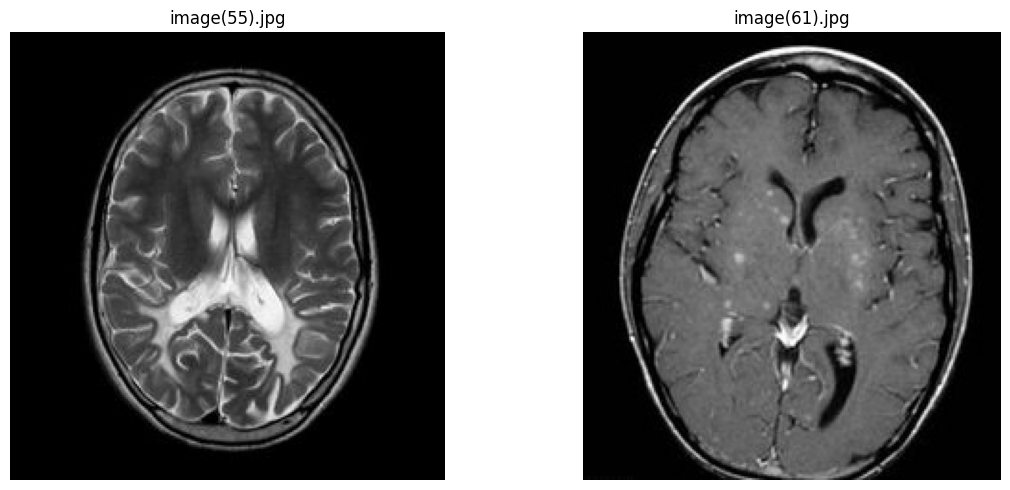

In [12]:
#Visualisation des 2 images sans annotations
images_a_verifier = [
      images_dir / "image(55).jpg",
      images_dir / "image(61).jpg",
]

fig, axes = plt.subplots(1, 2, figsize=(12,5))

for ax, chemin in zip(axes, images_a_verifier):
      image = cv2.imread(str(chemin))

      if image is None:
            ax.set_title(f"Impossible de lire\n{chemin.name}")
            ax.axis("off")
            continue

      image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      ax.imshow(image_rgb, cmap='gray')
      ax.set_title(chemin.name)
      ax.axis('off')

plt.tight_layout()


In [13]:

exemples = [
    "Tr-no_0025",
    "Tr-no_0042",
    "Tr-no_0048",
]

for nom in exemples:
    fichier = labels_dir / f"{nom}.txt"

    print(f"\n--- {nom}.txt ---")

    if fichier.exists():
        contenu = fichier.read_text(encoding="utf-8").strip()
        print(contenu if contenu else "Annotation vide")
    else:
        print("Annotation introuvable")



--- Tr-no_0025.txt ---
2 0.505656 0.504525 0.653846 0.760181

--- Tr-no_0042.txt ---
2 0.497881 0.513761 0.605932 0.807339

--- Tr-no_0048.txt ---
2 0.495726 0.520089 0.581197 0.700893


In [14]:
def create_clean_dataset_dir(DATASET_DIR):
      CLEAN_DATASET_DIR = Path('/workspace/NeuroVision_AI_Partie_3/dataset_cleaned')

      if CLEAN_DATASET_DIR.exists():
            print('La copie nettoyée existe déja:', CLEAN_DATASET_DIR)
            print("verifier son contenue avant de continuer")

      else:
            # shutil.copytree() copie un dossier et son contenu vers un autre emplacement.
            shutil.copytree(DATASET_DIR, CLEAN_DATASET_DIR)
            print('Copie crée avec success')
      return CLEAN_DATASET_DIR
CLEAN_DATASET_DIR = create_clean_dataset_dir(DATASET_DIR)


Copie crée avec success


In [15]:
def remove_misMatch_images(fichiers_a_supprimer):
      for fichier in fichiers_a_supprimer:
            if fichier.is_file():
                  fichier.unlink()
                  print('Supprimé:', fichier.relative_to(CLEAN_DATASET_DIR))
            else:
                  print('Fichier introuvable:', fichier)

dossier_no_tumor = CLEAN_DATASET_DIR / "Val" / "No Tumor"

fichiers_a_supprimer = [
      dossier_no_tumor / "images" / "image(55).jpg",
      dossier_no_tumor / "images" / "image(61).jpg",
      dossier_no_tumor / "labels" / "image(53).txt",
      dossier_no_tumor / "labels" / "image(60).txt",
]

remove_misMatch_images(fichiers_a_supprimer=fichiers_a_supprimer)

def verify_removed_files(fichiers):
      for fichier in fichiers:
            statut = "Encore présent" if fichier.exists() else "Supprimé"
            print(f"{fichier.name} --> {statut}")

verify_removed_files(fichiers_a_supprimer)

Supprimé: Val/No Tumor/images/image(55).jpg
Supprimé: Val/No Tumor/images/image(61).jpg
Supprimé: Val/No Tumor/labels/image(53).txt
Supprimé: Val/No Tumor/labels/image(60).txt
image(55).jpg --> Supprimé
image(61).jpg --> Supprimé
image(53).txt --> Supprimé
image(60).txt --> Supprimé


In [16]:
nbr_classes = 4

CLASSES_IDS_VALIDES = set(range(nbr_classes))
print('Identifiants autoris"es pour les classes:', CLASSES_IDS_VALIDES)

Identifiants autoris"es pour les classes: {0, 1, 2, 3}


In [17]:
import math

def verifier_fichier_annotation(fichier, classes_ids_valides):
      erreurs = []

      contenue = fichier.read_text(encoding='utf-8')

      if not contenue:
            return erreurs

      for numero_ligne, ligne in enumerate(contenue.splitlines(), start=1):

            valeurs = ligne.split()

            if(len(valeurs) != 5):
                  erreurs.append(
                        f"Line{numero_ligne} : "
                        f" {len(valeurs)} valeurs au lieu de 5"
                  )
                  continue

            class_str, *cordonnees_str = valeurs

            try:
                  classe_float = float(class_str)

                  if not math.isfinite(classe_float) or not classe_float.is_integer():
                        erreurs.append(
                              f"Ligne {numero_ligne} : classe non entier"
                        )
                        continue
                  classe = int(classe_float)

            except ValueError:
                  erreurs.append(
                        f"Ligne {numero_ligne} : classe non numerique"
                  )
                  continue

            if classe not in classes_ids_valides:
                  erreurs.append(
                        f"Ligne {numero_ligne} : class invalide ({classe})"
                  )
                  continue

            try:
                  x_center, y_center, largeur, hauteur = map(float, cordonnees_str)

            except ValueError:
                  erreurs.append(
                        f"Ligne {numero_ligne} : classe non numerique"
                        )
                  continue

            conrdonnees = [x_center, y_center, largeur, hauteur]

            if not all(math.isfinite(v) for v in conrdonnees):
                  erreurs.append(
                        f"Ligne {numero_ligne} : valeur non finie"
                  )
                  continue

            if not (0 <= x_center <= 1 and 0 <= y_center <= 1):
                  erreurs.append(
                        f"Ligne {numero_ligne} : centre hors limites"
                  )
            if not (0 <= largeur <= 1 and 0 <= hauteur <= 1):
                  erreurs.append(
                  f"Ligne {numero_ligne} : largeur ou hauteur hors limites"
                  )

            if (
                  0 <= largeur <= 1 
                  and 0 <= hauteur <= 1
                  and
                  (
                        x_center - largeur / 2 < 0
                        or x_center + largeur / 2 > 1
                        or y_center - hauteur / 2 < 0
                        or y_center + hauteur / 2 > 1
                  )
            ):
                  erreurs.append(
                        f"Ligne {numero_ligne} : boite deppasant les limites"
                  )
      return erreurs

In [18]:

def auditer_annotations(CLEAN_DATASET_DIR):
      total_fichiers = 0
      total_erreurs = 0
      fichiers_invalides = []

      for split in ["Train", "Val"]:
            split_dir = CLEAN_DATASET_DIR / split
            print(f"\n{'=' * 15} {split} {'=' * 15}")

            for classe_dir in sorted(split_dir.iterdir()):
                  if not classe_dir.is_dir():
                        continue

                  labels_dir = classe_dir / "labels"

                  if not labels_dir.is_dir():
                        print("Dossier labels introuvable :", classe_dir)
                        continue

                  for fichier in sorted(labels_dir.glob("*.txt")):
                        total_fichiers += 1

                        erreurs = verifier_fichier_annotation(
                        fichier,
                        CLASSES_IDS_VALIDES
                        )

                        if erreurs:
                              fichiers_invalides.append(fichier)
                              total_erreurs += len(erreurs)

                              print(f"\nFichier : {fichier.relative_to(CLEAN_DATASET_DIR)}")
                              for erreur in erreurs:
                                    print("  -", erreur)

      print("\n========== BILAN ==========")
      print("Fichiers TXT vérifiés :", total_fichiers)
      print("Fichiers contenant des erreurs :", len(fichiers_invalides))
      print("Nombre total d'erreurs :", total_erreurs)

      return fichiers_invalides


fichiers_invalides = auditer_annotations(CLEAN_DATASET_DIR)



=============== Train ===============

Fichier : Train/No Tumor/labels/3.txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/Tr-noTr_0000.txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/Tr-no_0810.txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/Tr-no_0988.txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/Tr-no_1083.txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image (11).txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image (58).txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image(110).txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image(116).txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image(231).txt
  - Ligne 1 : boite deppasant les limites

Fichier : Train/No Tumor/labels/image(317).txt
  - Ligne 1 : boite 

In [19]:
CLASS_NAMES = {
      0: "Glioma",
      1: "Meningioma",
      2: "No Tumor",
      3: "Pituitary",
}
print(CLASS_NAMES)

{0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


In [20]:
def afficher_image_bbox(image_path, label_path):

      image = cv2.imread(str(image_path))

      if image is None:
            print(f"Image impossible de lire : {image_path}")
            return

      image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      hauteur, largeur = image.shape[:2]

      with open (label_path, 'r', encoding='utf-8') as fichier:
            lignes = fichier.readlines()

            for ligne in lignes:
                  valeurs  = ligne.split()

                  if len(valeurs) != 5:
                        continue

                  classe, x_center, y_center, w, h = map(float, valeurs)

                  x_center *= largeur
                  y_center *= hauteur
                  w *=largeur
                  h *= hauteur

                  x1 = int(x_center - w / 2) 
                  y1 = int(y_center - h / 2) 
                  x2 = int(x_center + w / 2) 
                  y2 = int(y_center + h / 2) 

                  x1 = max(0, min(x1, largeur -1))
                  y1 = max(0, min(y1, hauteur -1))
                  x2 = max(0, min(x2, largeur -1))
                  y2 = max(0, min(y2, hauteur -1))

                  classe_id = int(classe)

                  nom_classe = CLASS_NAMES.get(classe_id, f'Classe {classe_id}')

                  cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

                  cv2.putText(
                        image,
                        nom_classe,
                        (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 0, 0),
                        2
                  )


                  plt.figure(figsize=(7,7))
                  plt.imshow(image)
                  plt.title(image_path.name)
                  plt.axis('off')
                  plt.show()




Classe du dossier : Glioma


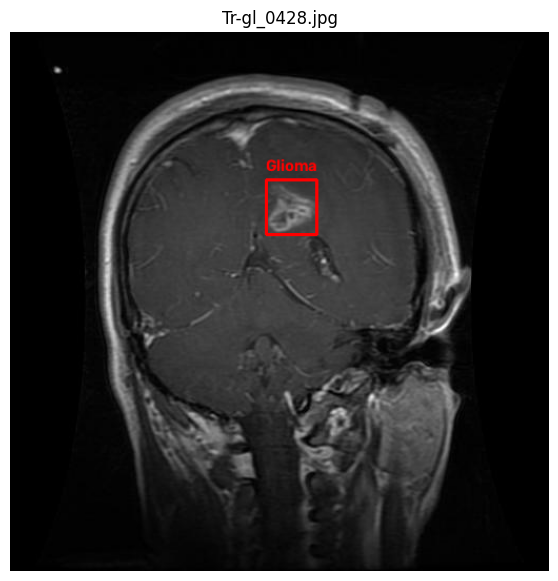

Classe du dossier : Meningioma


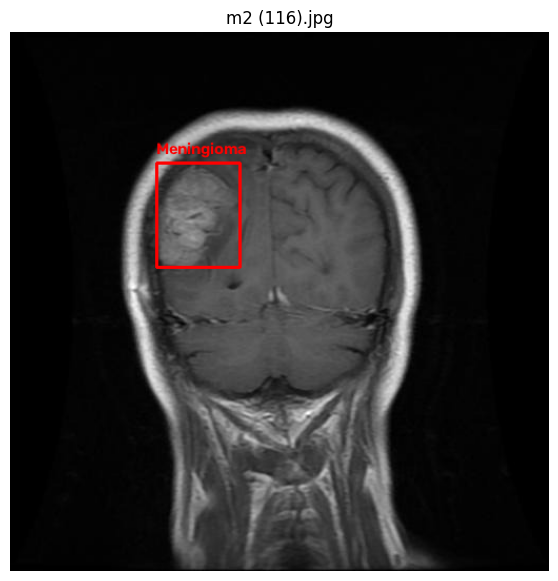

Classe du dossier : No Tumor


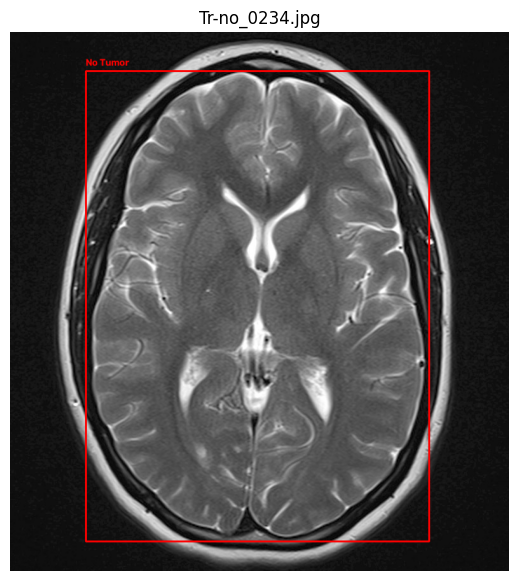

Classe du dossier : Pituitary


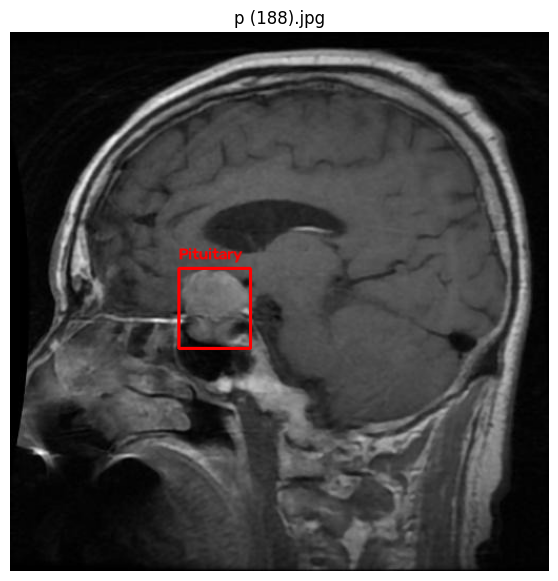

In [21]:
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

for classe in CLASSES:
      dossier_images = CLEAN_DATASET_DIR / "Train" / classe / "images"
      dossier_labels = CLEAN_DATASET_DIR / "Train" / classe / "labels"

      images = [
            p for p in dossier_images.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            and (dossier_labels / f"{p.stem}.txt").is_file()
      ]

      if not images:
            print(f"Aucune image annotée trouvée pour {classe}")
            continue

      image_path = random.choice(images)
      label_path = dossier_labels / f"{image_path.stem}.txt"

      print(f"Classe du dossier : {classe}")
      afficher_image_bbox(image_path, label_path)

In [22]:
# Analyser la distribution des classes
from pathlib import Path
import pandas as pd

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
SPLITS = ["Train", "Val"]

statistiques = []

for split in SPLITS:
      for classe in CLASSES:
            dossier_images = CLEAN_DATASET_DIR / split / classe / "images"

            images = [
                  fichier
                  for fichier in dossier_images.iterdir()
                  if fichier.is_file()
                  and fichier.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            ]

            statistiques.append({
                  "Split": split,
                  "Classe": classe,
                  "Nombre_images": len(images)
            })

df_stats = pd.DataFrame(statistiques)

display(df_stats)

,Split,Classe,Nombre_images
0,Train,Glioma,1153
1,Train,Meningioma,1449
2,Train,No Tumor,711
3,Train,Pituitary,1424
4,Val,Glioma,136
5,Val,Meningioma,140
6,Val,No Tumor,98
7,Val,Pituitary,136


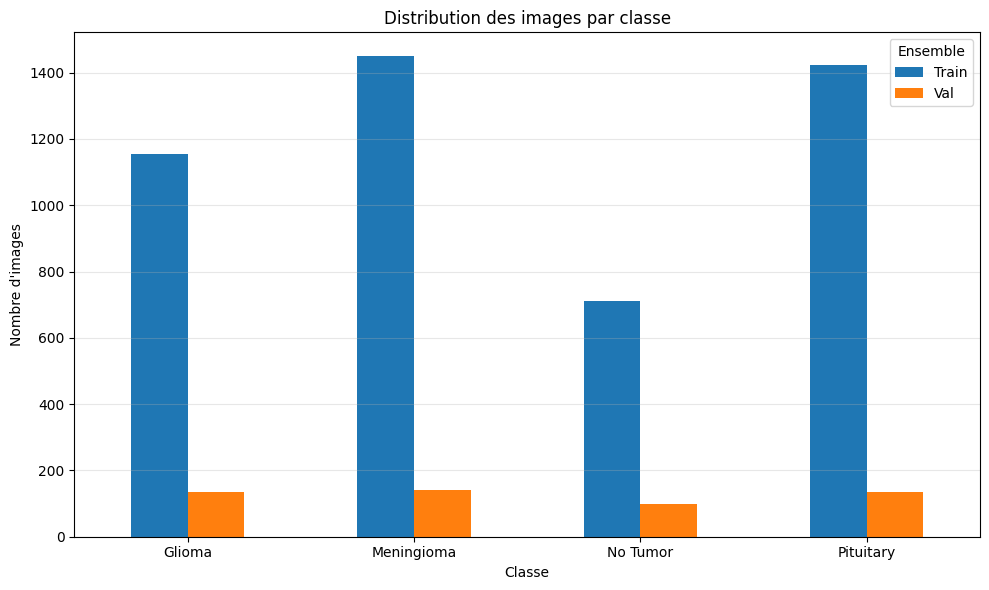

In [23]:
# Visualiser la répartition des images
tableau = df_stats.pivot(
      index="Classe",
      columns="Split",
      values="Nombre_images"
)

tableau.plot(
      kind="bar",
      figsize=(10, 6),
      rot=0
)

plt.title("Distribution des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.legend(title="Ensemble")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
def identifier_annotations_vides(CLEAN_DATASET_DIR):
    print("ok")
    annotations_vides = []

    for split in ["Train", "Val"]:
        split_dir = CLEAN_DATASET_DIR / split

        for classe_dir in sorted(split_dir.iterdir()):
            if not classe_dir.is_dir():
                continue

            labels_dir = classe_dir / "labels"
            images_dir = classe_dir / "images"

            if not labels_dir.is_dir() or not images_dir.is_dir():
                continue

            for fichier_label in sorted(labels_dir.glob("*.txt")):
                contenu = fichier_label.read_text(
                    encoding="utf-8"
                ).strip()

                if contenu == "":
                    images_associees = [
                        image for image in images_dir.iterdir()
                        if image.is_file()
                        and image.stem == fichier_label.stem
                        and image.suffix.lower()
                        in {".jpg", ".jpeg", ".png", ".bmp"}
                    ]

                    annotations_vides.append({
                        "label": fichier_label,
                        "images": images_associees,
                        "classe": classe_dir.name,
                        "split": split
                    })
    print("Annotations vides trouvées :", len(annotations_vides))

    for element in annotations_vides:
        print(
            element["split"],
            "|", element["classe"],
            "|", element["label"].name,
            "| Images correspondantes :", len(element["images"])
        )

    return annotations_vides

In [25]:
def supprimer_annotations_vides(annotations_vides):
    nb_labels_supprimes = 0
    nb_images_supprimees = 0
    nb_sans_image = 0

    for element in annotations_vides:
        fichier_label = element["label"]
        images_associees = element["images"]

        if not fichier_label.is_file():
            continue

        # Supprimer le fichier d'annotation vide
        fichier_label.unlink()
        nb_labels_supprimes += 1

        if not images_associees:
            nb_sans_image += 1

        # Supprimer aussi les images associées
        for image in images_associees:
            if image.is_file():
                image.unlink()
                nb_images_supprimees += 1

    print("Annotations vides supprimées :", nb_labels_supprimes)
    print("Images supprimées :", nb_images_supprimees)
    print("Annotations sans image associée :", nb_sans_image)

    return {
        "labels_supprimes": nb_labels_supprimes,
        "images_supprimees": nb_images_supprimees,
        "labels_sans_image": nb_sans_image
    }

bilan_annotations_vides = supprimer_annotations_vides(
    identifier_annotations_vides(CLEAN_DATASET_DIR)
)

ok
Annotations vides trouvées : 1
Val | Glioma | gg (342).txt | Images correspondantes : 1
Annotations vides supprimées : 1
Images supprimées : 1
Annotations sans image associée : 0


#### Organisation du dataset

In [26]:
#Créer la structure du dataset
def create_yolo_dataset_dir(CLEAN_DATASET_DIR):
      YOLO_DATASET_DIR = Path(
            "/workspace/NeuroVision_AI_Partie_3/dataset_yolo"
      )

      if not CLEAN_DATASET_DIR.exists():
            raise FileNotFoundError(
                  f"Dataset nettoyé introuvable : {CLEAN_DATASET_DIR}"
            )

      for split in ["train", "val", "test"]:
            for sous_dossier in ["images", "labels"]:
                  dossier = YOLO_DATASET_DIR / sous_dossier / split
                  dossier.mkdir(parents=True, exist_ok=True)

      print("Structure du dataset YOLO créée avec succès.")
      print("Chemin :", YOLO_DATASET_DIR)

      return YOLO_DATASET_DIR
YOLO_DATASET_DIR = create_yolo_dataset_dir(CLEAN_DATASET_DIR)

Structure du dataset YOLO créée avec succès.
Chemin : /workspace/NeuroVision_AI_Partie_3/dataset_yolo


In [27]:
def verifier_structure_yolo(YOLO_DATASET_DIR):
      for split in ["train", "val", "test"]:
            print(f"\n--- {split.upper()} ---")

            for sous_dossier in ["images", "labels"]:
                  dossier = YOLO_DATASET_DIR / sous_dossier / split

                  print(
                  f"{sous_dossier} : "
                  f"{'Présent' if dossier.is_dir() else 'Absent'}"
            )

verifier_structure_yolo(YOLO_DATASET_DIR)


--- TRAIN ---
images : Présent
labels : Présent

--- VAL ---
images : Présent
labels : Présent

--- TEST ---
images : Présent
labels : Présent


In [28]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import shutil

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

RANDOM_SEED = 42

def collecter_paires(split_dir):

    #Récupère les images et leurs fichiers d'annotations dans chaque dossier de classe.
    
    paires = []

    for classe_dir in sorted(split_dir.iterdir()):
        if not classe_dir.is_dir():
            continue

        images_dir = classe_dir / "images"
        labels_dir = classe_dir / "labels"

        for image_path in sorted(images_dir.iterdir()):
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            label_path = labels_dir / f"{image_path.stem}.txt"

            if not label_path.exists():
                raise FileNotFoundError(
                    f"Annotation manquante pour : {image_path}"
                )

            paires.append({
                "image": image_path,
                "label": label_path,
                "classe": classe_dir.name
            })

    return paires


def copier_paires(paires, YOLO_DATASET_DIR, split):
     #Copie chaque image et son annotation dans les dossiers YOLO. Ajoute un préfixe pour éviter les collisions de noms.
    
    for paire in paires:
        image_path = paire["image"]
        label_path = paire["label"]
        classe = paire["classe"]

        nouveau_nom = f"{split}_{classe}_{image_path.stem}"

        destination_image = (
            YOLO_DATASET_DIR / "images" / split /
            f"{nouveau_nom}{image_path.suffix.lower()}"
        )

        destination_label = (
            YOLO_DATASET_DIR / "labels" / split /
            f"{nouveau_nom}.txt"
        )

        shutil.copy2(image_path, destination_image)
        shutil.copy2(label_path, destination_label)


def preparer_dataset_yolo(CLEAN_DATASET_DIR, YOLO_DATASET_DIR):
    #Sépare Train en train/test et conserve Val pour la validation.

    train_dir = CLEAN_DATASET_DIR / "Train"
    val_dir = CLEAN_DATASET_DIR / "Val"

    if not train_dir.exists() or not val_dir.exists():
        raise FileNotFoundError("Dossier Train ou Val introuvable.")

    # Récupérer les paires
    paires_train = collecter_paires(train_dir)
    paires_val = collecter_paires(val_dir)

    if not paires_train or not paires_val:
        raise ValueError("Le dataset ne contient pas assez de données.")

    # Répartition stratifiée de Train
    classes = [paire["classe"] for paire in paires_train]

    paires_train_final, paires_test = train_test_split(
        paires_train,
        test_size=0.15,
        random_state=RANDOM_SEED,
        stratify=classes
    )

    # Vérifier que les dossiers de destination sont vides
    for dossier in [
        YOLO_DATASET_DIR / "images",
        YOLO_DATASET_DIR / "labels"
    ]:
        for fichier in dossier.rglob("*"):
            if fichier.is_file():
                raise FileExistsError(
                    "Le dataset YOLO contient déjà des fichiers. "
                    "Évite de relancer la copie sans nettoyer "
                    "le dataset de destination."
                )

    # Copier les données
    copier_paires(paires_train_final, YOLO_DATASET_DIR, "train")
    copier_paires(paires_val, YOLO_DATASET_DIR, "val")
    copier_paires(paires_test, YOLO_DATASET_DIR, "test")

    print("Préparation du dataset YOLOv8 terminée.")
    print(f"Train : {len(paires_train_final)} images")
    print(f"Val   : {len(paires_val)} images")
    print(f"Test  : {len(paires_test)} images")

    return paires_train_final, paires_val, paires_test


In [29]:
paires_train, paires_val, paires_test = preparer_dataset_yolo(
    CLEAN_DATASET_DIR,
    YOLO_DATASET_DIR
)


Préparation du dataset YOLOv8 terminée.
Train : 4026 images
Val   : 509 images
Test  : 711 images


In [30]:
# Vérifier les effectifs par classe

import pandas as pd

def afficher_repartition(paires_train, paires_val, paires_test):

    donnees = []

    for split, paires in [
        ("Train", paires_train),
        ("Val", paires_val),
        ("Test", paires_test)
    ]:
        for paire in paires:
            donnees.append({
                "Split": split,
                "Classe": paire["classe"]
            })

    df_repartition = pd.DataFrame(donnees)

    tableau = pd.crosstab(
        df_repartition["Classe"],
        df_repartition["Split"]
    )

    print("Répartition des images par classe :")
    display(tableau)

    return tableau


df_repartition = afficher_repartition(
    paires_train,
    paires_val,
    paires_test
)


Répartition des images par classe :


Split,Test,Train,Val
Classe,,,
Glioma,173,980,135
Meningioma,217,1232,140
No Tumor,107,604,98
Pituitary,214,1210,136


In [31]:

import yaml

def creer_data_yaml(YOLO_DATASET_DIR):

    YOLO_DATASET_DIR = Path(YOLO_DATASET_DIR)

    data_config = {
        "path": str(YOLO_DATASET_DIR),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "nc": 4,
        "names": {
            0: "Glioma",
            1: "Meningioma",
            2: "No Tumor",
            3: "Pituitary"
        }
    }

    yaml_path = YOLO_DATASET_DIR / "data.yaml"

    with open(yaml_path, "w", encoding="utf-8") as fichier:
        yaml.dump(
            data_config,
            fichier,
            sort_keys=False,
            allow_unicode=True
        )

    print("Fichier data.yaml créé :", yaml_path)

    return yaml_path


DATA_YAML_PATH = creer_data_yaml(YOLO_DATASET_DIR)


Fichier data.yaml créé : /workspace/NeuroVision_AI_Partie_3/dataset_yolo/data.yaml


In [32]:

def verifier_data_yaml(DATA_YAML_PATH):

    with open(DATA_YAML_PATH, "r", encoding="utf-8") as fichier:
        configuration = yaml.safe_load(fichier)

    print("Contenu du fichier data.yaml :")
    print(yaml.dump(
        configuration,
        sort_keys=False,
        allow_unicode=True
    ))

    return configuration


data_config = verifier_data_yaml(DATA_YAML_PATH)


Contenu du fichier data.yaml :
path: /workspace/NeuroVision_AI_Partie_3/dataset_yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary



In [33]:

def verifier_images_yolo(YOLO_DATASET_DIR):

    for split in ["train", "val", "test"]:

        images_dir = YOLO_DATASET_DIR / "images" / split
        labels_dir = YOLO_DATASET_DIR / "labels" / split

        images = [
            f for f in images_dir.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ]

        labels = list(labels_dir.glob("*.txt"))

        print(f"\n{split.upper()}")
        print(f"Images      : {len(images)}")
        print(f"Annotations : {len(labels)}")

        if len(images) != len(labels):
            print("Attention : nombre d'images et d'annotations différent.")
        else:
            print("Nombre de fichiers cohérent.")


verifier_images_yolo(YOLO_DATASET_DIR)



TRAIN
Images      : 4026
Annotations : 4026
Nombre de fichiers cohérent.

VAL
Images      : 509
Annotations : 509
Nombre de fichiers cohérent.

TEST
Images      : 711
Annotations : 711
Nombre de fichiers cohérent.


In [34]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

def afficher_image_yolo(image_path, label_path, class_names):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Impossible de lire : {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    hauteur, largeur = image.shape[:2]

    with open(label_path, "r", encoding="utf-8") as fichier:
        lignes = fichier.readlines()

    for ligne in lignes:

        valeurs = ligne.strip().split()

        if len(valeurs) != 5:
            continue

        class_id = int(valeurs[0])
        x_center, y_center, width, height = map(float, valeurs[1:])

        x_center *= largeur
        y_center *= hauteur
        width *= largeur
        height *= hauteur

        x1 = int(x_center - width / 2)
        y1 = int(y_center - height / 2)
        x2 = int(x_center + width / 2)
        y2 = int(y_center + height / 2)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        nom_classe = class_names[class_id]

        cv2.putText(
            image,
            nom_classe,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.show()


#### Data Augmentation

In [35]:

# Configuration de Data Augmentation pour les IRM cérébrales

AUGMENTATION_CONFIG = {
    "degrees": 5.0,
    "translate": 0.05,
    "scale": 0.10,

    "fliplr": 0.0,
    "flipud": 0.0,

    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.10,

    "mosaic": 0.0,
    "mixup": 0.0,
    "copy_paste": 0.0,    
}

print("Configuration Data Augmentation :")

for parametre, valeur in AUGMENTATION_CONFIG.items():
    print(f"{parametre} : {valeur}")


Configuration Data Augmentation :
degrees : 5.0
translate : 0.05
scale : 0.1
fliplr : 0.0
flipud : 0.0
hsv_h : 0.0
hsv_s : 0.0
hsv_v : 0.1
mosaic : 0.0
mixup : 0.0
copy_paste : 0.0


In [36]:

def analyser_image(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Image impossible à lire : {image_path}")

    hauteur, largeur, canaux = image.shape

    print("Chemin :", image_path)
    print("Dimensions :", largeur, "x", hauteur)
    print("Canaux :", canaux)
    print("Pixel minimum :", image.min())
    print("Pixel maximum :", image.max())
    print("Moyenne des pixels :", round(image.mean(), 2))

    return image


image_test = next(
    (YOLO_DATASET_DIR / "images" / "train").glob("*")
)

image_originale = analyser_image(image_test)


Chemin : /workspace/NeuroVision_AI_Partie_3/dataset_yolo/images/train/train_Meningioma_m2 (65).jpg
Dimensions : 512 x 512
Canaux : 3
Pixel minimum : 0
Pixel maximum : 255
Moyenne des pixels : 51.59


In [37]:
IMAGE_SIZE = 512

PROJECT_DIR = Path("/workspace/NeuroVision_AI_Partie_3/yolo_training")
RUN_NAME = "yolov8n_brain_tumor"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
AUGMENTATION_PREVIEW_CONFIG = {
    # Model
    # --------------------------------------------------------
    "model": "yolov8n.pt",

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------
    "data": str(DATA_YAML_PATH),

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    "epochs": 10,
    "batch": 32,
    "imgsz": 512,

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------
    "patience": 3,

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    "optimizer": "AdamW",
    "lr0": 0.001,
    "weight_decay": 5e-4,

    # --------------------------------------------------------
    # Hardware
    # --------------------------------------------------------
    "device": 0 if torch.cuda.is_available() else "cpu",
    "workers": 2,
    "cache": True,

    # Mixed Precision
    "amp": True,

    "project": str(PROJECT_DIR),
    "name": "augmentation_preview",
    "exist_ok": True,

    "plots": True,
    "save": True,
    "verbose": True,

    **AUGMENTATION_CONFIG
}


In [38]:

#def tester_augmentations(model="yolov8n.pt", config):
#
#    print("Début du test des augmentations...")
#
#    results = model.train(**config)
#
#    print("Test terminé.")
#
#    return results
#
#
#augmentation_results = tester_augmentations(
#    model=model,
#    config=AUGMENTATION_PREVIEW_CONFIG
#)


In [39]:

def afficher_batches_augmentes(PROJECT_DIR):

    batch_dir = PROJECT_DIR / "augmentation_preview"

    fichiers_batches = sorted(
        batch_dir.glob("train_batch*.jpg")
    )

    if not fichiers_batches:
        print("Aucune image de batch trouvée.")
        print("Vérifie que plots=True et que l'entraînement s'est terminé.")
        return

    for fichier in fichiers_batches:

        image = cv2.imread(str(fichier))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(14, 10))
        plt.imshow(image)
        plt.title(fichier.name)
        plt.axis("off")
        plt.show()


afficher_batches_augmentes(PROJECT_DIR)


Aucune image de batch trouvée.
Vérifie que plots=True et que l'entraînement s'est terminé.


In [40]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
TRAIN_CONFIG = {
    # Dataset
    "data": str(DATA_YAML_PATH),

    # Entraînement
    "epochs": 10,
    "imgsz": IMAGE_SIZE,
    "batch": 32,
    "patience": 4,

    # Matériel
    "device": DEVICE,

    # Optimisation
    "optimizer": "auto",
    "pretrained": True,

    # Augmentations
    **AUGMENTATION_CONFIG,

    # Sauvegarde
    "project": str(PROJECT_DIR),
    "name": "yolov8n_brain_tumor_final",
    "exist_ok": False,
    "save": True,
    "plots": True,
    "verbose": True
}

def afficher_configuration(config):
    print("CONFIGURATION DE L'ENTRAÎNEMENT")
    print("-" * 40)

    for parametre, valeur in config.items():
        print(f"{parametre}: {valeur}")


afficher_configuration(TRAIN_CONFIG)

CONFIGURATION DE L'ENTRAÎNEMENT
----------------------------------------
data: /workspace/NeuroVision_AI_Partie_3/dataset_yolo/data.yaml
epochs: 10
imgsz: 512
batch: 32
patience: 4
device: 0
optimizer: auto
pretrained: True
degrees: 5.0
translate: 0.05
scale: 0.1
fliplr: 0.0
flipud: 0.0
hsv_h: 0.0
hsv_s: 0.0
hsv_v: 0.1
mosaic: 0.0
mixup: 0.0
copy_paste: 0.0
project: /workspace/NeuroVision_AI_Partie_3/yolo_training
name: yolov8n_brain_tumor_final
exist_ok: False
save: True
plots: True
verbose: True


#### Entraînement de YOLOV8


Classe : Glioma


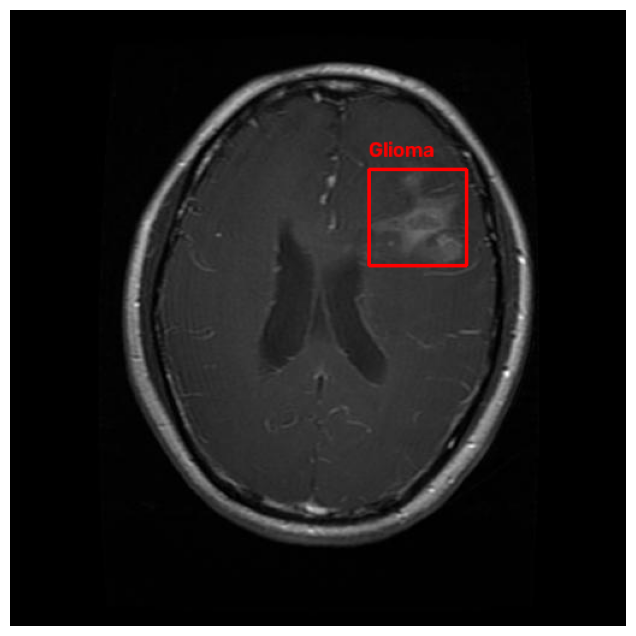

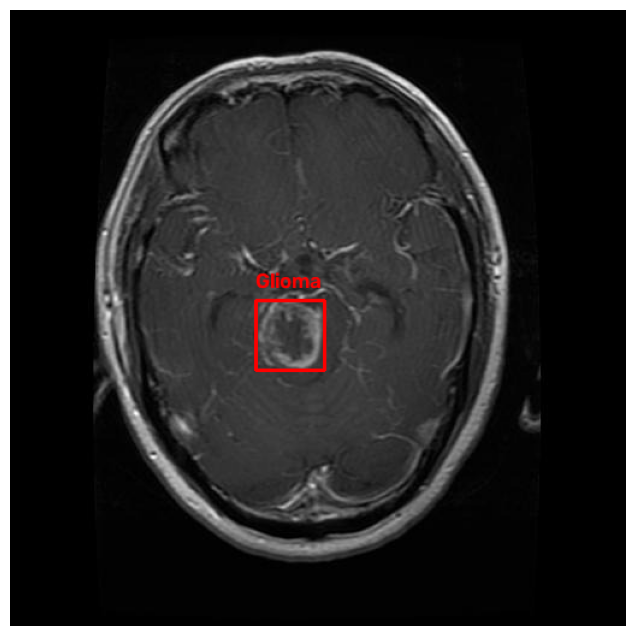


Classe : Meningioma


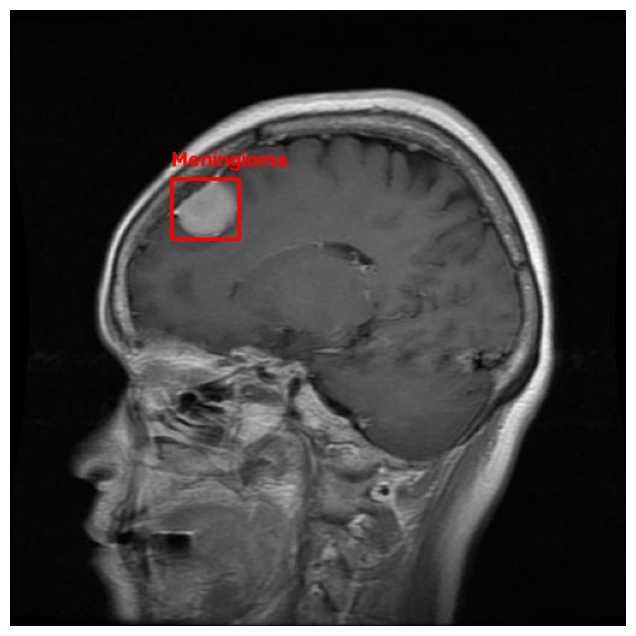

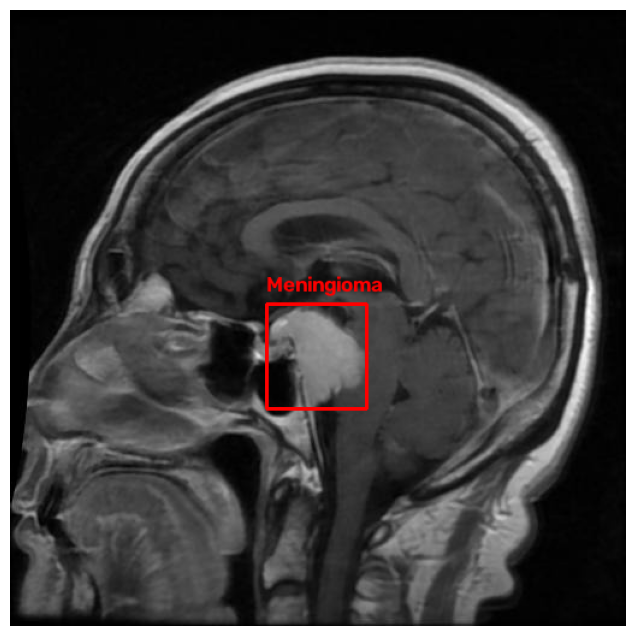


Classe : No Tumor


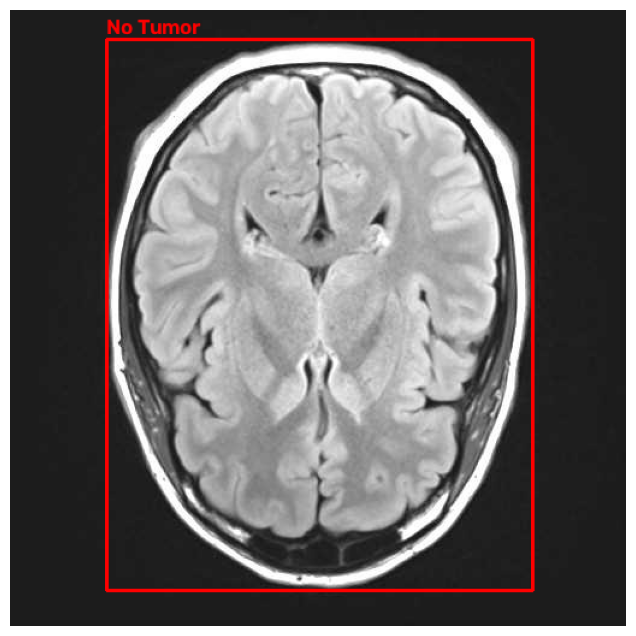

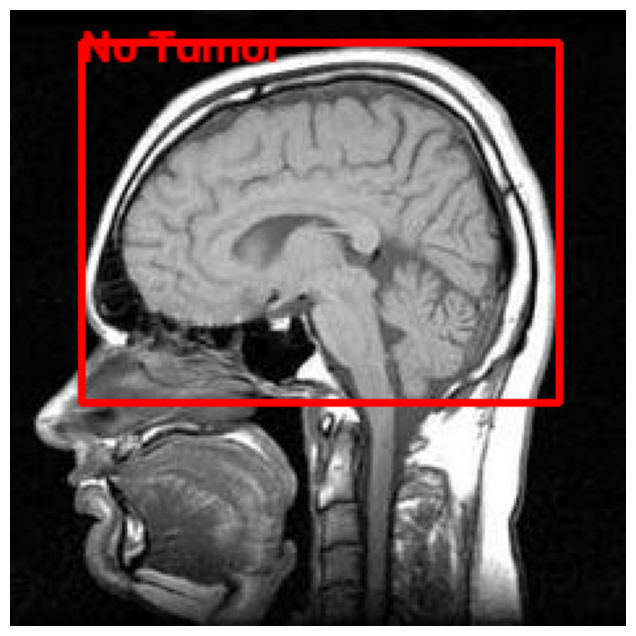


Classe : Pituitary


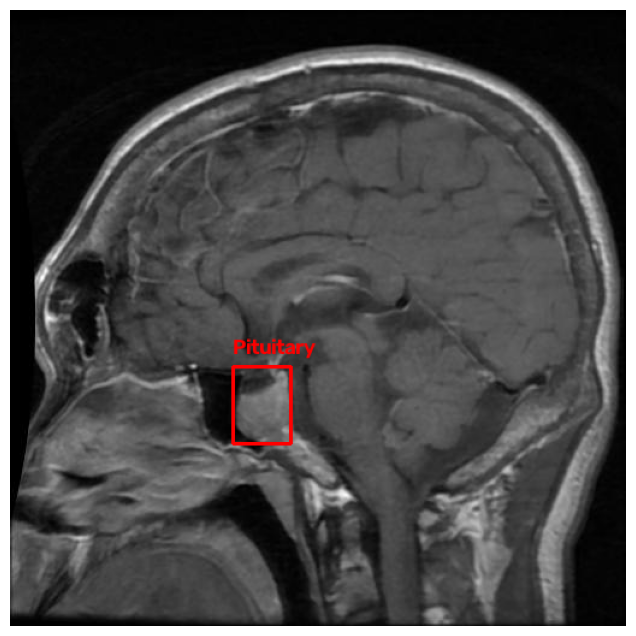

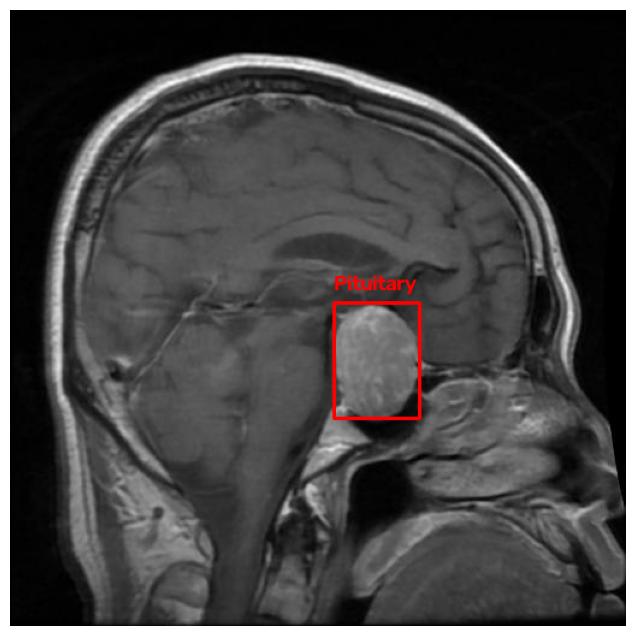

In [41]:

def visualiser_exemples_yolo(YOLO_DATASET_DIR, split="train", n=2):

    images_dir = YOLO_DATASET_DIR / "images" / split

    for classe in CLASS_NAMES.values():

        images_classe = [
            image for image in images_dir.iterdir()
            if image.is_file()
            and image.stem.startswith(f"{split}_{classe}_")
        ]

        print(f"\nClasse : {classe}")

        for image_path in images_classe[:n]:

            label_path = (
                YOLO_DATASET_DIR / "labels" / split /
                f"{image_path.stem}.txt"
            )

            afficher_image_yolo(
                image_path,
                label_path,
                CLASS_NAMES
            )


visualiser_exemples_yolo(YOLO_DATASET_DIR, split="train", n=2)


In [42]:

import torch
import ultralytics
import time
from ultralytics import YOLO

In [43]:

def charger_modele_yolo(model_name="yolov8n.pt"):

    model = YOLO(model_name)

    print(f"Modèle chargé : {model_name}")

    return model


model = charger_modele_yolo()

model.info()


Modèle chargé : yolov8n.pt
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [44]:

EPOCHS = 10
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 10
DEVICE = 0 if torch.cuda.is_available() else "cpu"

PROJECT_DIR = Path("/NeuroVision_AI_Partie_3/yolo_training")
RUN_NAME = "yolov8n_brain_tumor"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration définie.")
print("Epochs :", EPOCHS)
print("Image size :", IMAGE_SIZE)
print("Batch size :", BATCH_SIZE)
print("Device :", DEVICE)
print("Project directory :", PROJECT_DIR)


Configuration définie.
Epochs : 10
Image size : 640
Batch size : 16
Device : 0
Project directory : /NeuroVision_AI_Partie_3/yolo_training


In [45]:
def entrainer_modele_yolo(config, model=model):

    # Charger un nouveau modèle pré-entraîné

    print("Début de l'entraînement YOLOv8...")
    debut = time.perf_counter()

    # Entraînement
    results = model.train(**config)

    fin = time.perf_counter()
    duree = fin - debut

    heures = int(duree // 3600)
    minutes = int((duree % 3600) // 60)
    secondes = int(duree % 60)

    print("\nEntraînement terminé !")
    print(f"Durée totale : {heures}h {minutes}min {secondes}s")

    return model, results, duree


model_final, training_results, training_duration = entrainer_modele_yolo(
    config=TRAIN_CONFIG
)

Début de l'entraînement YOLOv8...
Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 48590MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/NeuroVision_AI_Partie_3/dataset_yolo/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_

2026/10/30 11:16:04 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


MLflow: logging run_id(ca9f6149994043369a441f8de7550cb7) to sqlite:////workspace/NeuroVision_AI_Partie_3/notebooks/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 4026 train, 509 val images for fraction=1.0 at imgsz=512
Using 8 dataloader workers
Logging results to /workspace/NeuroVision_AI_Partie_3/yolo_training/yolov8n_brain_tumor_final
Starting training for 10 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/10      2.35G      1.071      3.321      1.227         27        512: 100% ━━━━━━━━━━━━ 126/126 12.3it/s 10.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.6s0.1ss
                   all        509        554      0.518      0.591      0.573      0.378

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10      2.96G     0.9871     0.9153      1.141         29        512: 

#### Évaluation et analyse des erreurs

In [47]:

BEST_MODEL_PATH = (
    PROJECT_DIR / RUN_NAME / "weights" / "best.pt"
)

def charger_meilleur_modele(BEST_MODEL_PATH):

    BEST_MODEL_PATH = Path(BEST_MODEL_PATH)

    if not BEST_MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Modèle introuvable : {BEST_MODEL_PATH}"
        )

    best_model = YOLO(str(BEST_MODEL_PATH))

    print("Meilleur modèle chargé avec succès.")

    return best_model


best_model = charger_meilleur_modele('/workspace/NeuroVision_AI_Partie_3/yolo_training/yolov8n_brain_tumor_final/weights/best.pt')


Meilleur modèle chargé avec succès.


In [48]:
# Évaluer le modèle sur Test
def evaluer_modele_yolo(
    model,
    DATA_YAML_PATH,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE
):

    metrics = model.val(
        data=str(DATA_YAML_PATH),
        split="test",
        imgsz=imgsz,
        batch=batch,
        device=device,
        plots=True,
        verbose=True
    )

    print("Évaluation sur le jeu de test terminée.")

    return metrics


test_metrics = evaluer_modele_yolo(
    model=best_model,
    DATA_YAML_PATH=DATA_YAML_PATH
)


Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 48590MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 741.9±210.5 MB/s, size: 28.0 KB)
val: Scanning /workspace/NeuroVision_AI_Partie_3/dataset_yolo/labels/test... 711 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 711/711 2.5Kit/s 0.3s0.2ss
val: New cache created: /workspace/NeuroVision_AI_Partie_3/dataset_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 13.3it/s 3.4s0.0s
                   all        711        795      0.885      0.838      0.921      0.641
                Glioma        173        198      0.922      0.715      0.875      0.619
            Meningioma        216        227      0.962      0.901      0.946      0.728
              No Tumor        107        107      0.733      0.963      0.952      0.588


In [49]:
# Afficher les résultats

def afficher_metriques_yolo(metrics):

    print("========== RÉSULTATS YOLOv8 ==========")

    print(f"Precision   : {metrics.box.mp:.4f}")
    print(f"Recall      : {metrics.box.mr:.4f}")
    print(f"mAP50       : {metrics.box.map50:.4f}")
    print(f"mAP50-95    : {metrics.box.map:.4f}")


afficher_metriques_yolo(test_metrics)


========== RÉSULTATS YOLOv8 ==========
Precision   : 0.8851
Recall      : 0.8384
mAP50       : 0.9211
mAP50-95    : 0.6414


In [50]:
# Visualiser les prédictions


def visualiser_predictions_yolo(model, YOLO_DATASET_DIR, n=5):

    images_dir = YOLO_DATASET_DIR / "images" / "test"

    images = sorted([
        str(image)
        for image in images_dir.iterdir()
        if image.suffix.lower() in IMAGE_EXTENSIONS
    ])

    if not images:
        raise ValueError("Aucune image disponible dans le dossier test.")

    images_selection = images[:n]

    results = model.predict(
        source=images_selection,
        imgsz=IMAGE_SIZE,
        conf=0.25,
        save=True,
        project=str(PROJECT_DIR),
        name="test_predictions",
        exist_ok=True
    )

    print("Prédictions enregistrées.")

    return results


predictions = visualiser_predictions_yolo(
    best_model,
    YOLO_DATASET_DIR,
    n=5
)



0: 640x640 1 Glioma, 1.1ms
1: 640x640 2 Gliomas, 1.1ms
2: 640x640 1 Glioma, 1.1ms
3: 640x640 2 Gliomas, 1.1ms
4: 640x640 2 Gliomas, 1.1ms
Speed: 1.1ms preprocess, 1.1ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /NeuroVision_AI_Partie_3/yolo_training/test_predictions
Prédictions enregistrées.


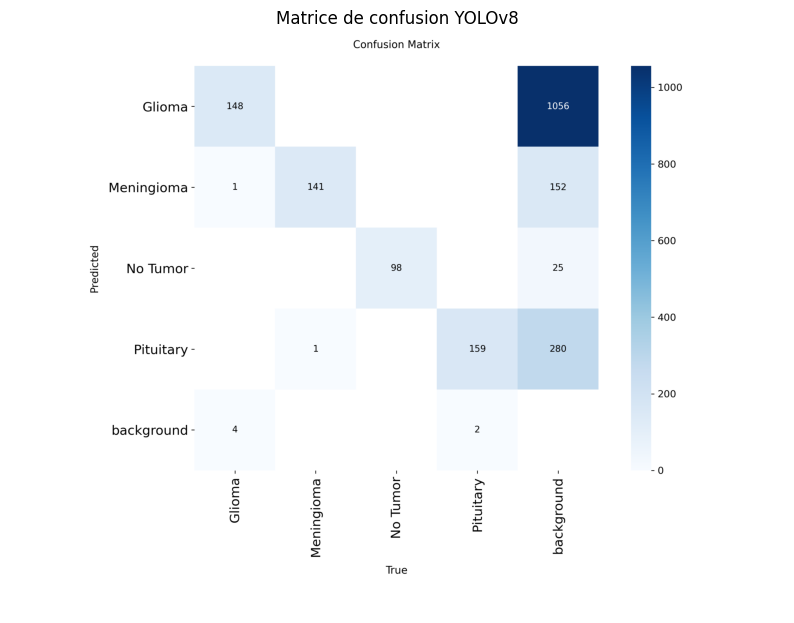

In [53]:
# Afficher la matrice de confusion


def afficher_matrice_confusion(PROJECT_DIR, RUN_NAME):

    confusion_path = Path('/workspace/NeuroVision_AI_Partie_3/yolo_training/yolov8n_brain_tumor_final/confusion_matrix.png')

    if not confusion_path.exists():
        print("Matrice de confusion introuvable.")
        return

    image = cv2.imread(str(confusion_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Matrice de confusion YOLOv8")
    plt.show()


afficher_matrice_confusion(PROJECT_DIR, RUN_NAME)


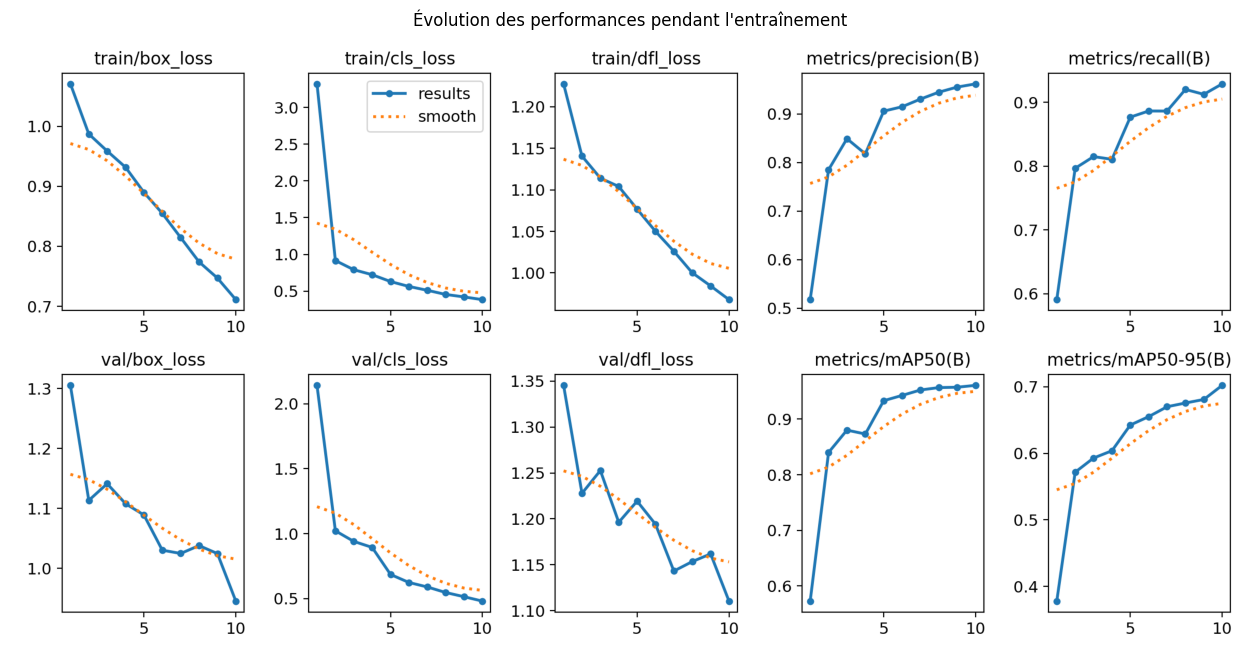

In [55]:
# Afficher les courbes d'entraînement

def afficher_courbes_entrainement(PROJECT_DIR, RUN_NAME):

    results_path = Path('/workspace/NeuroVision_AI_Partie_3/yolo_training/yolov8n_brain_tumor_final/results.png')

    if not results_path.exists():
        print("Graphique results.png introuvable.")
        return

    image = cv2.imread(str(results_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(16, 10))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Évolution des performances pendant l'entraînement")
    plt.show()


afficher_courbes_entrainement(PROJECT_DIR, RUN_NAME)


In [56]:
# Comparer les performances par classe

def afficher_metriques_par_classe(metrics):

    noms_classes = metrics.names
    precision = metrics.box.p
    recall = metrics.box.r
    map50 = metrics.box.ap50
    map5095 = metrics.box.ap

    donnees = []

    for class_id, nom in noms_classes.items():

        donnees.append({
            "Classe": nom,
            "Precision": round(float(precision[class_id]), 4),
            "Recall": round(float(recall[class_id]), 4),
            "mAP50": round(float(map50[class_id]), 4),
            "mAP50-95": round(float(map5095[class_id]), 4)
        })

    df = pd.DataFrame(donnees)

    display(df)

    return df


df_metriques_classes = afficher_metriques_par_classe(test_metrics)


,Classe,Precision,Recall,mAP50,mAP50-95
0,Glioma,0.9218,0.7145,0.8754,0.6193
1,Meningioma,0.9623,0.9008,0.9456,0.7276
2,No Tumor,0.7329,0.9626,0.9525,0.5880
3,Pituitary,0.9234,0.7757,0.9109,0.6307


In [ ]:

# Configuration de Data Augmentation pour les IRM cérébrales

AUGMENTATION_CONFIG = {
    "degrees": 5.0,
    "translate": 0.05,
    "scale": 0.10,

    "fliplr": 0.0,
    "flipud": 0.0,

    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.10,

    "mosaic": 0.0,
    "mixup": 0.0,
    "copy_paste": 0.0
}

print("Configuration Data Augmentation :")

for parametre, valeur in AUGMENTATION_CONFIG.items():
    print(f"{parametre} : {valeur}")


In [57]:

def analyser_image(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Image impossible à lire : {image_path}")

    hauteur, largeur, canaux = image.shape

    print("Chemin :", image_path)
    print("Dimensions :", largeur, "x", hauteur)
    print("Canaux :", canaux)
    print("Pixel minimum :", image.min())
    print("Pixel maximum :", image.max())
    print("Moyenne des pixels :", round(image.mean(), 2))

    return image


image_test = next(
    (YOLO_DATASET_DIR / "images" / "train").glob("*")
)

image_originale = analyser_image(image_test)


Chemin : /workspace/NeuroVision_AI_Partie_3/dataset_yolo/images/train/train_Meningioma_m2 (65).jpg
Dimensions : 512 x 512
Canaux : 3
Pixel minimum : 0
Pixel maximum : 255
Moyenne des pixels : 51.59


In [58]:

AUGMENTATION_PREVIEW_CONFIG = {
    "data": str(DATA_YAML_PATH),
    "epochs": 1,
    "imgsz": IMAGE_SIZE,
    "batch": 8,
    "device": DEVICE,

    "project": str(PROJECT_DIR),
    "name": "augmentation_preview",
    "exist_ok": True,

    "plots": True,
    "save": True,
    "verbose": True,

    **AUGMENTATION_CONFIG
}


In [59]:

def tester_augmentations(model, config):

    print("Début du test des augmentations...")

    results = model.train(**config)

    print("Test terminé.")

    return results


augmentation_results = tester_augmentations(
    model=model,
    config=AUGMENTATION_PREVIEW_CONFIG
)


Début du test des augmentations...
Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 48590MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/NeuroVision_AI_Partie_3/dataset_yolo/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/workspace/NeuroVision_AI_Partie_3/yolo_training

2026/10/30 11:23:11 INFO mlflow.tracking.fluent: Experiment with name '/NeuroVision_AI_Partie_3/yolo_training' does not exist. Creating a new experiment.
2026/10/30 11:23:11 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


MLflow: logging run_id(1c29477b9bd145fab8a88f75cabb9735) to sqlite:////workspace/NeuroVision_AI_Partie_3/notebooks/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 4026 train, 509 val images for fraction=1.0 at imgsz=640
Using 8 dataloader workers
Logging results to /NeuroVision_AI_Partie_3/yolo_training/augmentation_preview
Starting training for 1 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/1      1.13G     0.9831     0.8378      1.209          2        640: 100% ━━━━━━━━━━━━ 504/504 15.8it/s 31.8s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 7.6it/s 4.2s<0.1s
                   all        509        554      0.864      0.816      0.897      0.629

1 epochs completed in 0.011 hours.
Optimizer stripped from /NeuroVision_AI_Partie_3/yolo_training/augmentation_preview/weights/last.pt, 6.5MB
Optimizer stripped from /Neu

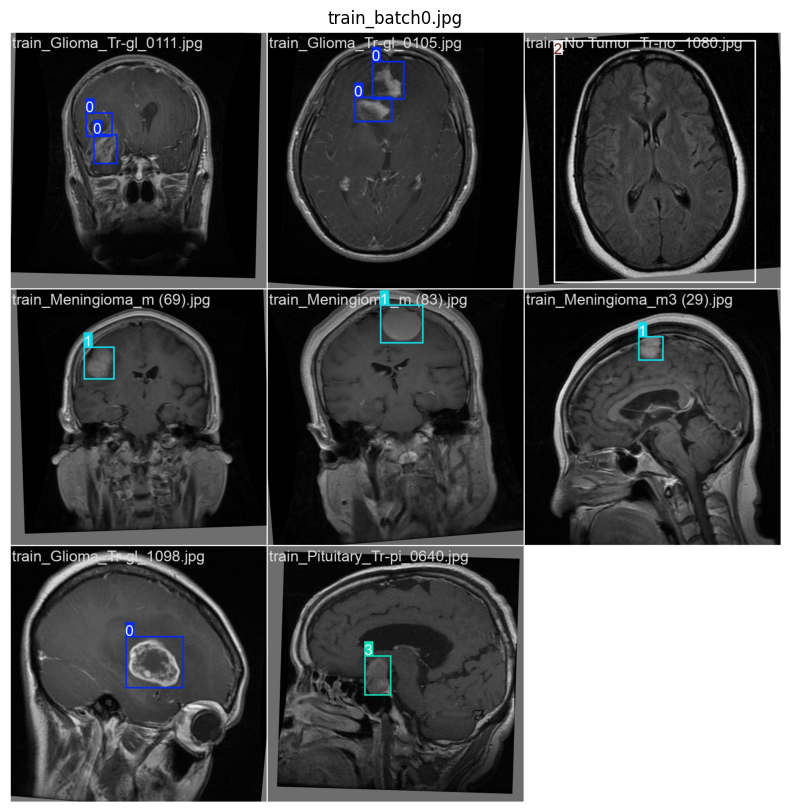

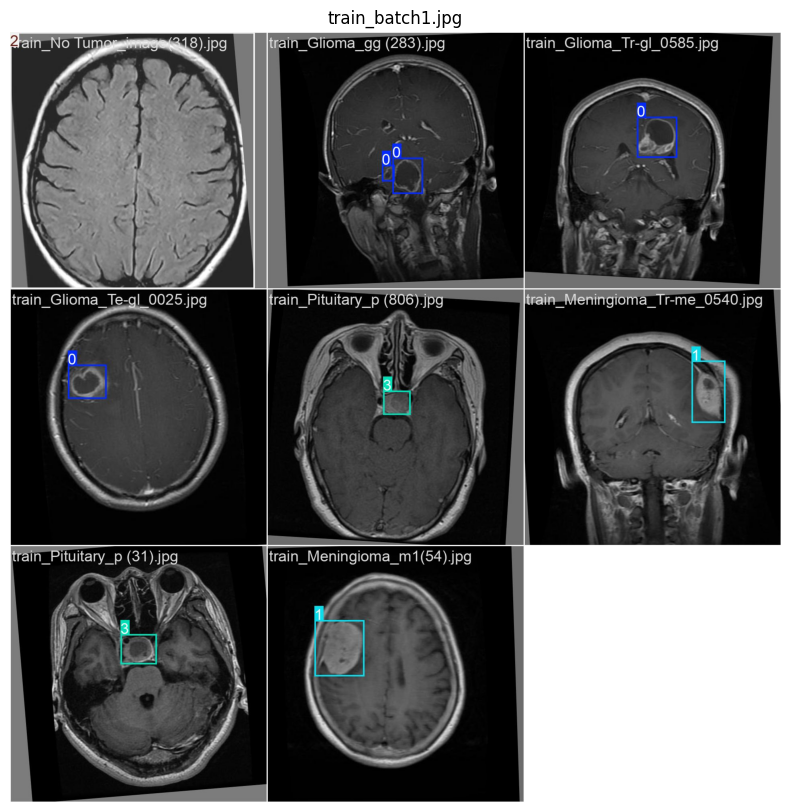

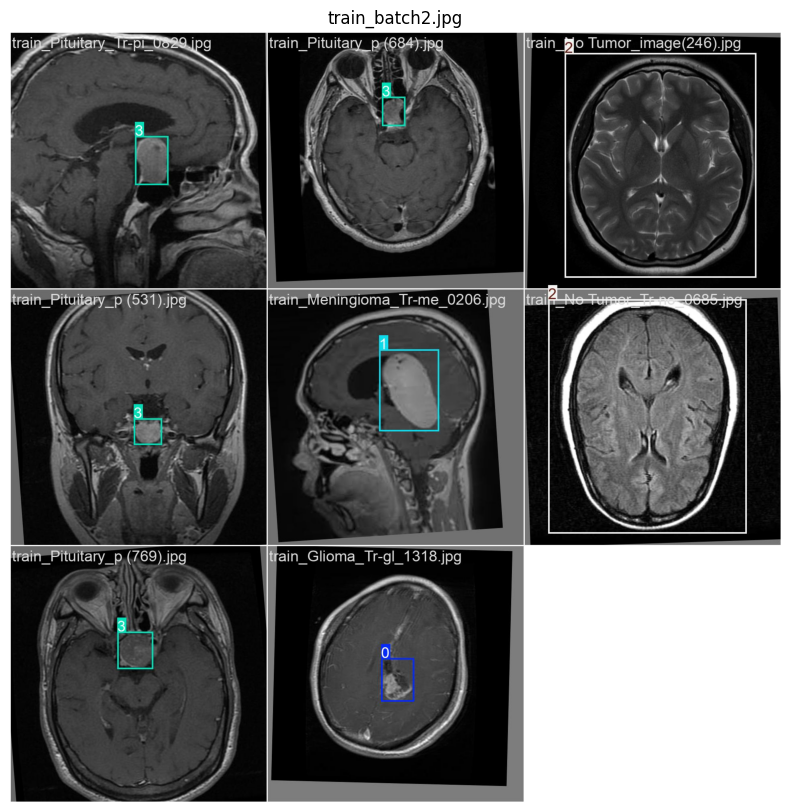

In [61]:

def afficher_batches_augmentes(PROJECT_DIR):

    batch_dir = PROJECT_DIR / "augmentation_preview"

    fichiers_batches = sorted(
        batch_dir.glob("train_batch*.jpg")
    )

    if not fichiers_batches:
        print("Aucune image de batch trouvée.")
        print("Vérifie que plots=True et que l'entraînement s'est terminé.")
        return

    for fichier in fichiers_batches:

        image = cv2.imread(str(fichier))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(14, 10))
        plt.imshow(image)
        plt.title(fichier.name)
        plt.axis("off")
        plt.show()


afficher_batches_augmentes(PROJECT_DIR)


In [62]:
TRAIN_CONFIG = {
    # Dataset
    "data": str(DATA_YAML_PATH),

    # Entraînement
    "epochs": 50,
    "imgsz": IMAGE_SIZE,
    "batch": 16,
    "patience": 10,

    # Matériel
    "device": DEVICE,

    # Optimisation
    "optimizer": "auto",
    "pretrained": True,

    # Augmentations
    **AUGMENTATION_CONFIG,

    # Sauvegarde
    "project": str(PROJECT_DIR),
    "name": "yolov8n_brain_tumor_final",
    "exist_ok": False,
    "save": True,
    "plots": True,
    "verbose": True
}

In [ ]:
def afficher_configuration(config):
    print("CONFIGURATION DE L'ENTRAÎNEMENT")
    print("-" * 40)

    for parametre, valeur in config.items():
        print(f"{parametre}: {valeur}")


afficher_configuration(TRAIN_CONFIG)

In [63]:
def calculer_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    largeur_intersection = max(0, x2 - x1)
    hauteur_intersection = max(0, y2 - y1)

    aire_intersection = (
        largeur_intersection * hauteur_intersection
    )

    aire_box1 = (
        max(0, box1[2] - box1[0])
        * max(0, box1[3] - box1[1])
    )

    aire_box2 = (
        max(0, box2[2] - box2[0])
        * max(0, box2[3] - box2[1])
    )

    aire_union = aire_box1 + aire_box2 - aire_intersection

    if aire_union == 0:
        return 0.0

    return aire_intersection / aire_union

In [64]:
boite_reelle = [100, 100, 200, 200]
boite_predite = [120, 120, 220, 220]

iou = calculer_iou(boite_reelle, boite_predite)

print(f"IoU : {iou:.3f}")

IoU : 0.471


#### Suivi des expériences avec MLflow